# For Reference

### AT - Ambient Temperature
### V - Exhaust Vacuum
### AP - Ambient pressure
### RH - Relative humidity
### PE - Electric  power Output

# **Importing Libraries and Loading Data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(r'../data/dataset.csv')

## Checking the structure of the dataset

In [2]:
# Basic information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (9568, 5)

Column names:
['AT', 'V', 'AP', 'RH', 'PE']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

First 5 rows:


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## Inspecting the data for missing values and Duplicates

In [3]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Total missing values: 0

Number of duplicate rows: 41


# Statistical Analysis of the Dataset

Mean:
AT      19.651231
V       54.305804
AP    1013.259078
RH      73.308978
PE     454.365009
dtype: float64
Median:
AT      20.345
V       52.080
AP    1012.940
RH      74.975
PE     451.550
dtype: float64
Standard Deviation:
AT     7.452473
V     12.707893
AP     5.938784
RH    14.600269
PE    17.066995
dtype: float64
Covariance:
            AT           V         AP          RH          PE
AT   55.539357   79.941324 -22.463437  -59.032171 -120.593715
V    79.941324  161.490544 -31.206771  -57.922808 -188.642778
AP  -22.463437  -31.206771  35.269152    8.633874   52.546510
RH  -59.032171  -57.922808   8.633874  213.167848   97.129952
PE -120.593715 -188.642778  52.546510   97.129952  291.282318
Correlation:
          AT         V        AP        RH        PE
AT  1.000000  0.844107 -0.507549 -0.542535 -0.948128
V   0.844107  1.000000 -0.413502 -0.312187 -0.869780
AP -0.507549 -0.413502  1.000000  0.099574  0.518429
RH -0.542535 -0.312187  0.099574  1.000000  0.389794
PE -0.948128 -

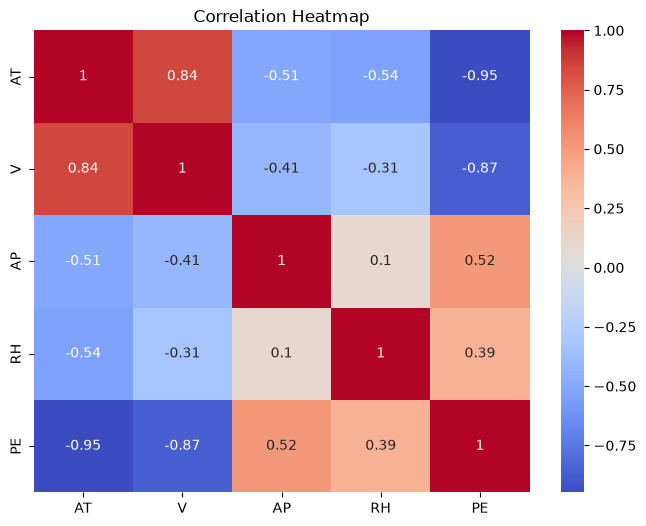

In [4]:
# Mean
print("Mean:")
print(df.mean())

# Median
print("Median:")
print(df.median())

# Standard deviation
print("Standard Deviation:")
print(df.std())

# Covariance
print("Covariance:")
print(df.cov())

# Correlation
print("Correlation:")
print(df.corr())

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Creating Project Directories

In [5]:
import os
folders = [
    "../plots/EDA",
    "../plots/Feature_Selection",
    "../plots/Model_Evaluation"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


# Data Preparation and Train-Test Split

In [6]:
# Duplicate values
print("Duplicates:", df.duplicated().sum())

# Remove duplicates if any
#df = df.drop_duplicates()
print(f"Dataset size after removing duplicates: {df.shape}")

X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training percentage:",
      len(X_train) / len(X) * 100)

print("Testing percentage:",
      len(X_test) / len(X) * 100)

Duplicates: 41
Dataset size after removing duplicates: (9568, 5)
Shape of X: (9568, 4)
Shape of y: (9568,)
Training features: (7654, 4)
Testing features: (1914, 4)
Training target: (7654,)
Testing target: (1914,)
Total samples: 9568
Training samples: 7654
Testing samples: 1914
Training percentage: 79.9958193979933
Testing percentage: 20.004180602006688


# Exploratory Data Analysis

AT : 0 outliers
V : 0 outliers
AP : 88 outliers
RH : 12 outliers
PE : 0 outliers


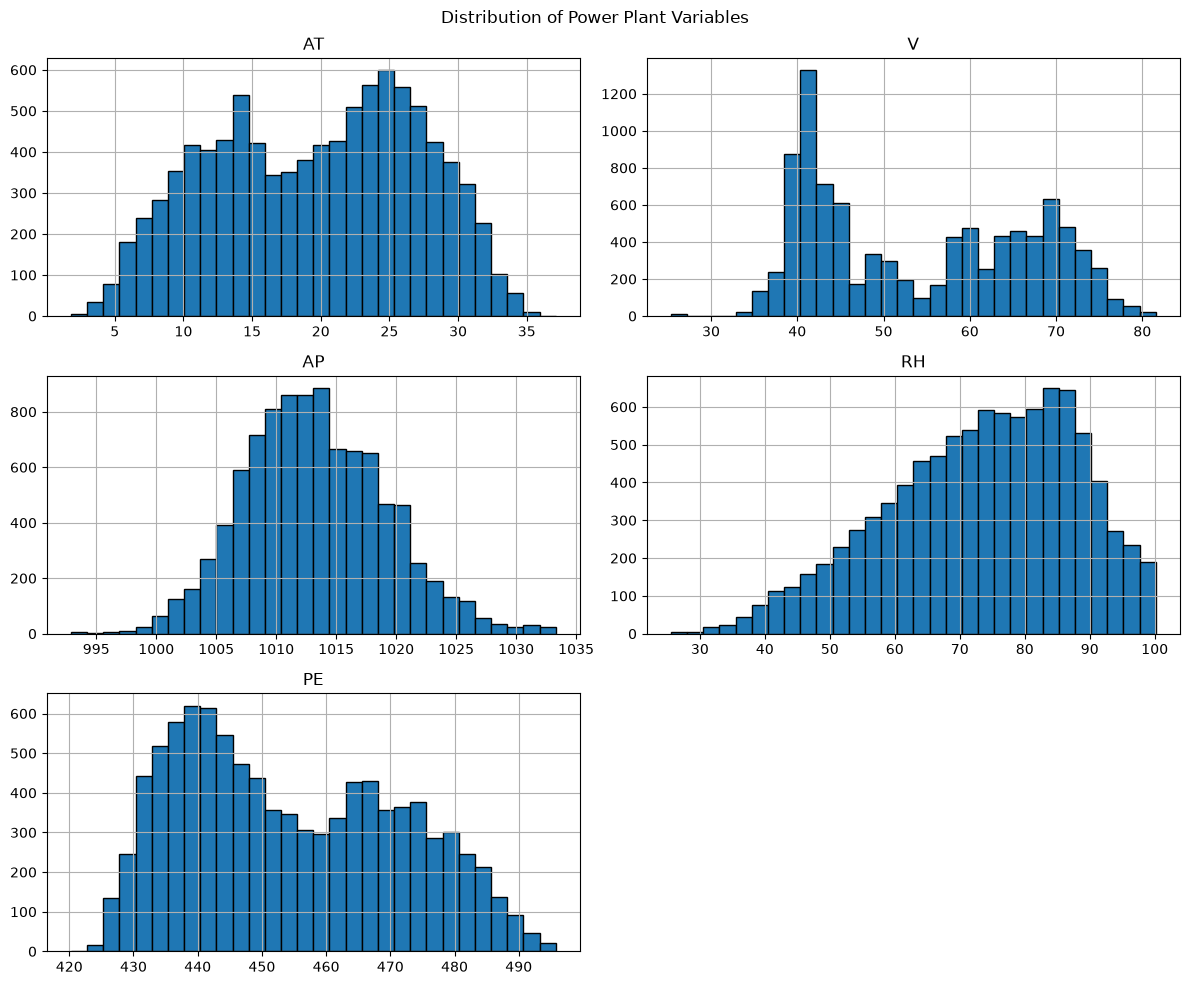

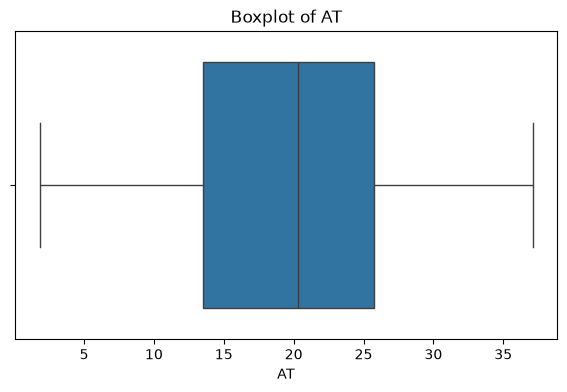

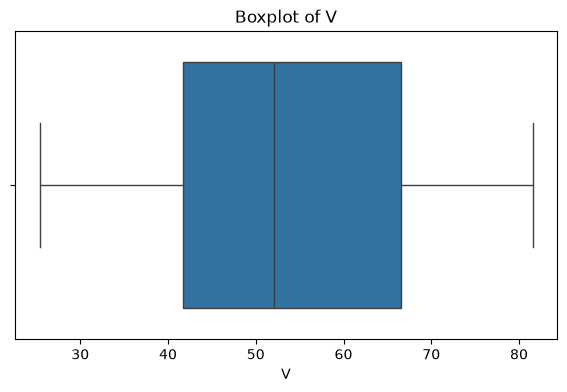

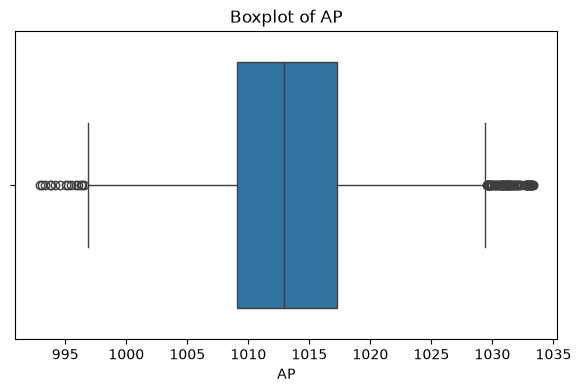

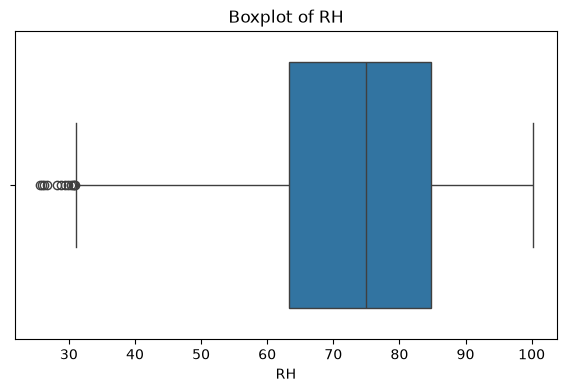

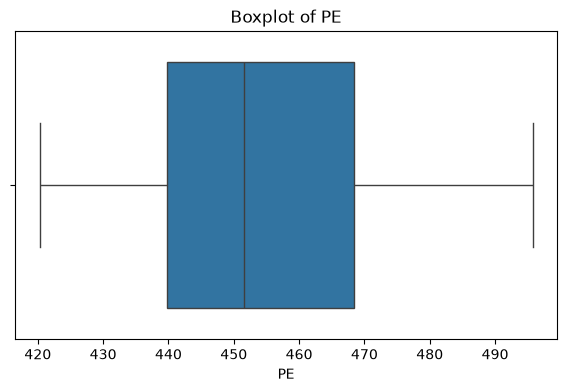

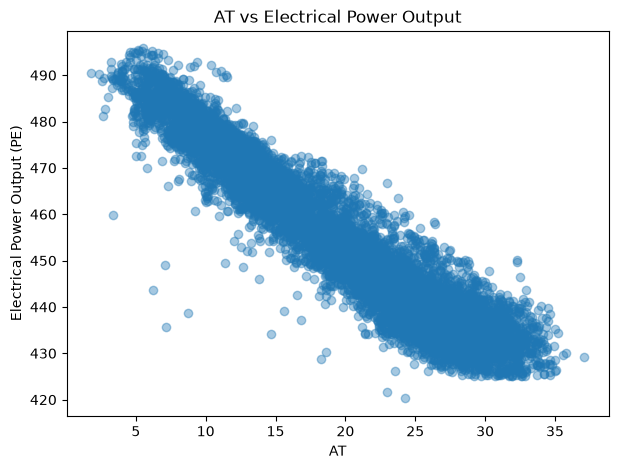

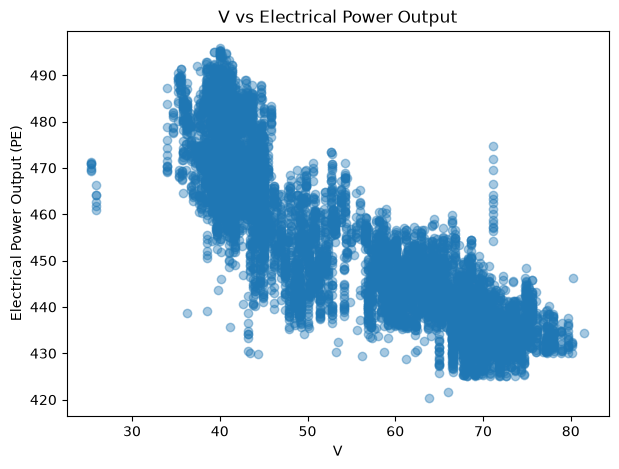

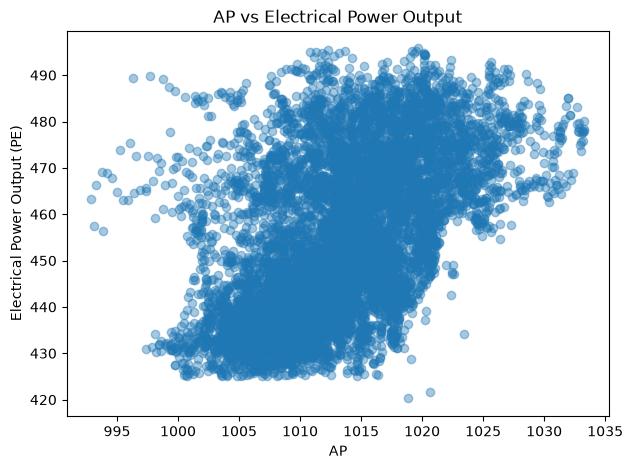

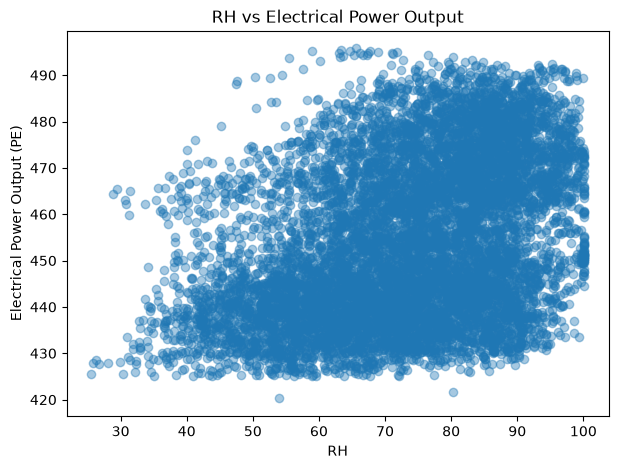

EDA plots saved successfully!
['boxplot_AP.png', 'boxplot_AT.png', 'boxplot_PE.png', 'boxplot_RH.png', 'boxplot_V.png', 'histograms.png', 'scatter_AP.png', 'scatter_AT.png', 'scatter_RH.png', 'scatter_V.png']


In [7]:
# Detect outliers using IQR

for col in df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

    # Histograms of all features

df.hist(
    figsize=(12, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Power Plant Variables")
plt.tight_layout()

plt.savefig("../plots/EDA/histograms.png")
plt.show()

# Individual boxplots

for col in df.columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[col])

    plt.title("Boxplot of " + col)
    plt.xlabel(col)

    plt.savefig("../plots/EDA/boxplot_" + col + ".png")
    plt.show()


features = ["AT", "V", "AP", "RH"]

for col in features:

    plt.figure(figsize=(7, 5))

    plt.scatter(df[col], df["PE"], alpha=0.4)

    plt.xlabel(col)
    plt.ylabel("Electrical Power Output (PE)")
    plt.title(col + " vs Electrical Power Output")

    plt.savefig("../plots/EDA/scatter_" + col + ".png")
    plt.show()



print("EDA plots saved successfully!")
print(os.listdir("../plots/EDA"))

Total combinations: 15
1 : ('AT',)
2 : ('V',)
3 : ('AP',)
4 : ('RH',)
5 : ('AT', 'V')
6 : ('AT', 'AP')
7 : ('AT', 'RH')
8 : ('V', 'AP')
9 : ('V', 'RH')
10 : ('AP', 'RH')
11 : ('AT', 'V', 'AP')
12 : ('AT', 'V', 'RH')
13 : ('AT', 'AP', 'RH')
14 : ('V', 'AP', 'RH')
15 : ('AT', 'V', 'AP', 'RH')
            Features  Number of Features        MAE         MSE       RMSE  \
0                 AT                   1   4.276723   28.912110   5.376998   
1                  V                   1   6.498810   69.979449   8.365372   
2                 AP                   1  12.026302  212.533533  14.578530   
3                 RH                   1  13.198207  246.025223  15.685191   
4             AT + V                   2   3.887221   24.068386   4.905954   
5            AT + AP                   2   4.275781   28.418942   5.330942   
6            AT + RH                   2   3.789240   22.653867   4.759608   
7             V + AP                   2   6.005697   60.128336   7.754246   
8     

,Features,Number of Features,MAE,MSE,RMSE,R2 Score
14,AT + V + AP + RH,4,3.595913,20.273706,4.502633,0.930105
11,AT + V + RH,3,3.599856,20.363791,4.512626,0.929794
6,AT + RH,2,3.789240,22.653867,4.759608,0.921899
12,AT + AP + RH,3,3.792631,22.655320,4.759761,0.921894
10,AT + V + AP,3,3.830200,23.354831,4.832684,0.919482
4,AT + V,2,3.887221,24.068386,4.905954,0.917022
5,AT + AP,2,4.275781,28.418942,5.330942,0.902023
0,AT,1,4.276723,28.912110,5.376998,0.900323
13,V + AP + RH,3,5.784484,55.636512,7.458989,0.808188
7,V + AP,2,6.005697,60.128336,7.754246,0.792702


Best feature combination: AT + V + AP + RH


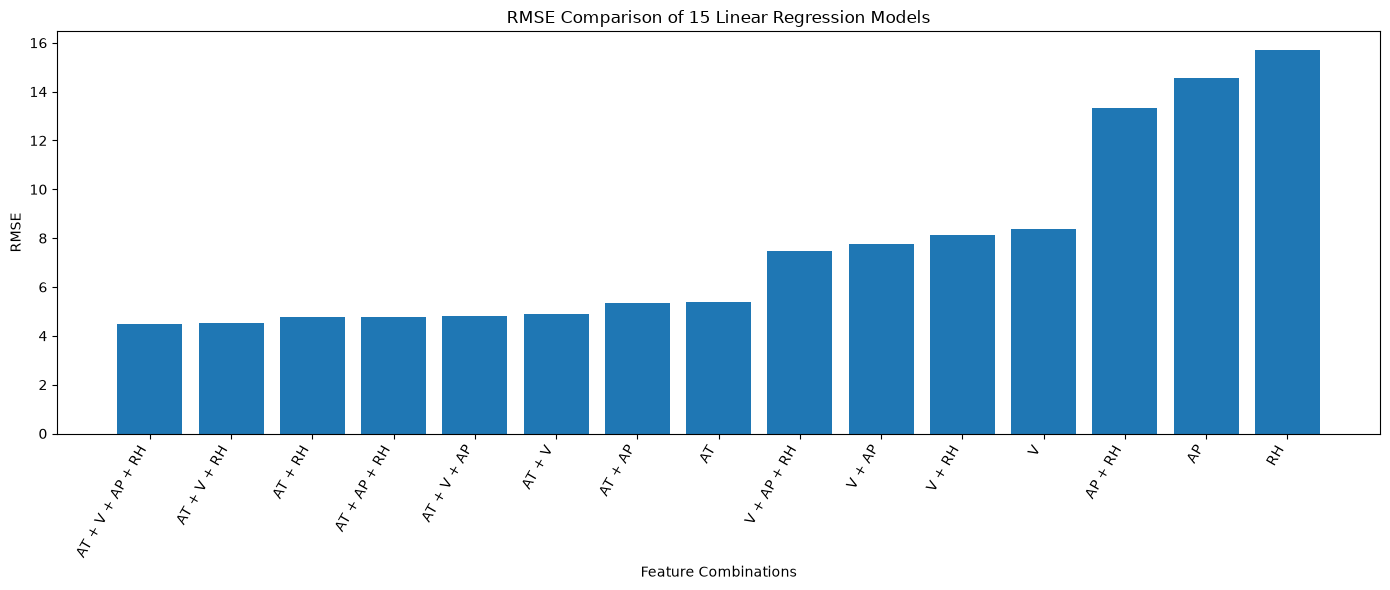

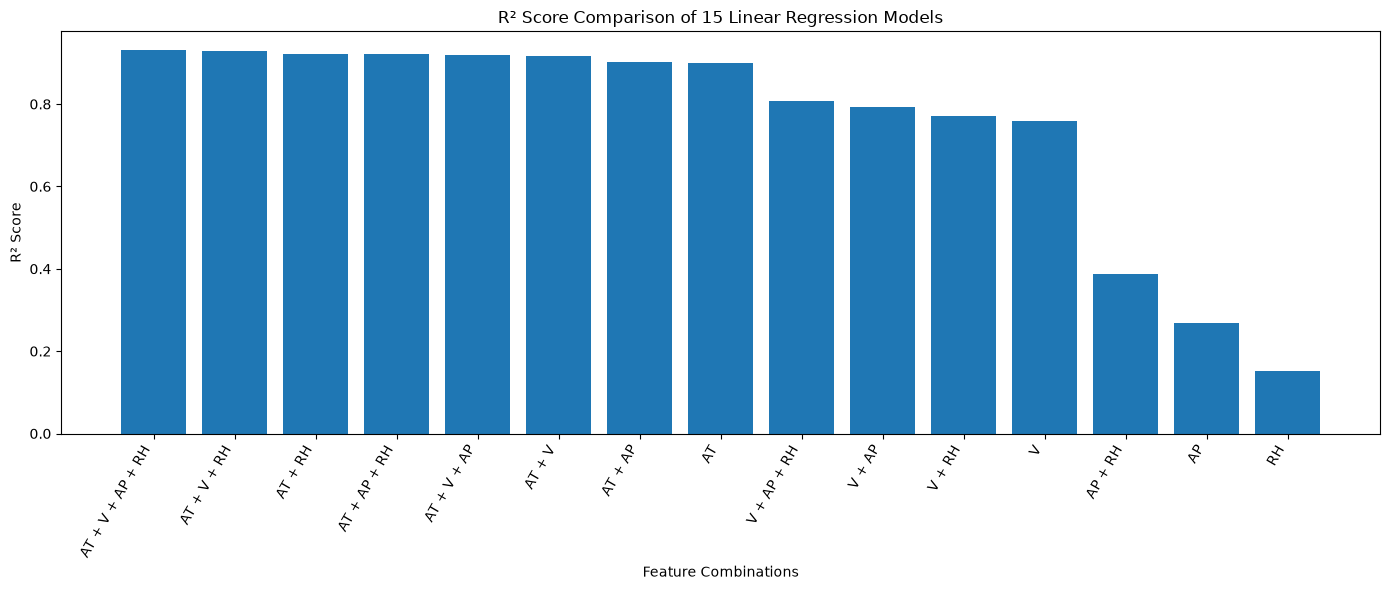

In [8]:
from itertools import combinations
features = ['AT', 'V', 'AP', 'RH']

feature_combinations = []

for r in range(1, 5):
    feature_combinations.extend(combinations(features, r))

print("Total combinations:", len(feature_combinations))

for i, combo in enumerate(feature_combinations, 1):
    print(i, ":", combo)

results = []

for combo in feature_combinations:
    X_train_selected = X_train[list(combo)]
    X_test_selected = X_test[list(combo)]

    model = LinearRegression()
    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Features': ' + '.join(combo),
        'Number of Features': len(combo),
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df)

results_df = results_df.sort_values(by='RMSE')

print("Models ranked by RMSE:")
display(results_df)

best_model_features = results_df.iloc[0]['Features']

print("Best feature combination:", best_model_features)

results_df.to_csv(
    "../plots/Feature_Selection/feature_comparison_results.csv",
    index=False
)



plt.figure(figsize=(14, 6))

plt.bar(results_df['Features'], results_df['RMSE'])

plt.xlabel("Feature Combinations")
plt.ylabel("RMSE")
plt.title("RMSE Comparison of 15 Linear Regression Models")

plt.xticks(rotation=60, ha='right')
plt.tight_layout()

plt.savefig(
    "../plots/Feature_Selection/RMSE_comparison.png"
)

plt.show()


plt.figure(figsize=(14, 6))

plt.bar(results_df['Features'], results_df['R2 Score'])

plt.xlabel("Feature Combinations")
plt.ylabel("R² Score")
plt.title("R² Score Comparison of 15 Linear Regression Models")

plt.xticks(rotation=60, ha='right')
plt.tight_layout()

plt.savefig(
    "../plots/Feature_Selection/R2_comparison.png"
)

plt.show()

Best features: ['AT', 'V', 'AP', 'RH']
Final Model Performance
-----------------------
MAE: 3.5959131782734084
MSE: 20.27370599968743
RMSE: 4.502633229532185
R2 Score: 0.9301046431962188
5-Fold Cross Validation Results
--------------------------------
Average MAE: 3.631877866079249
Average RMSE: 4.572397273712407
Average R2: 0.9282268261521758


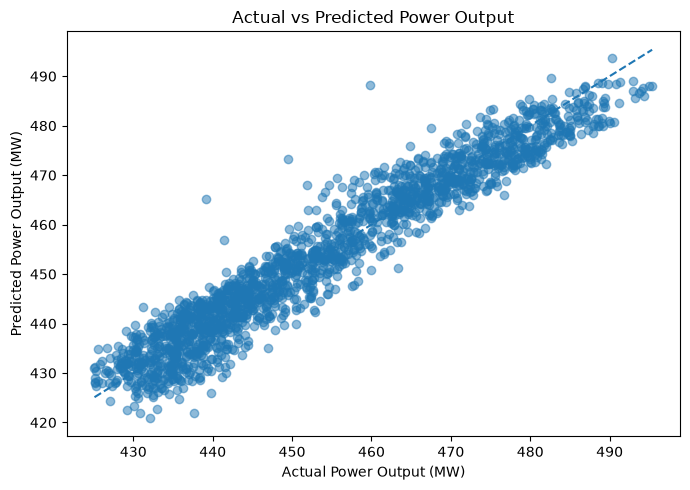

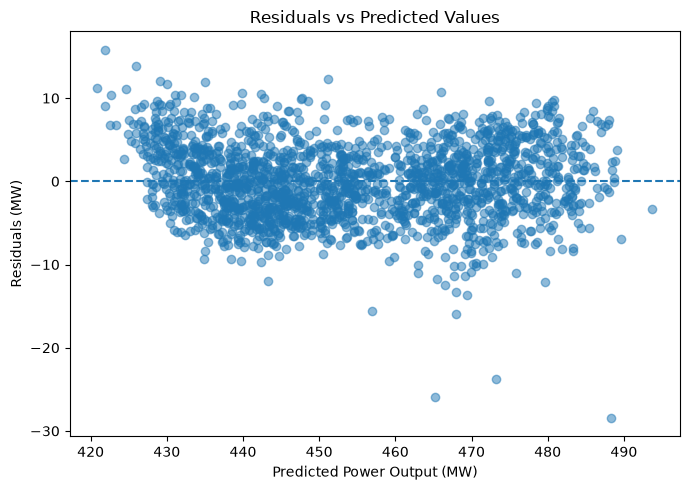

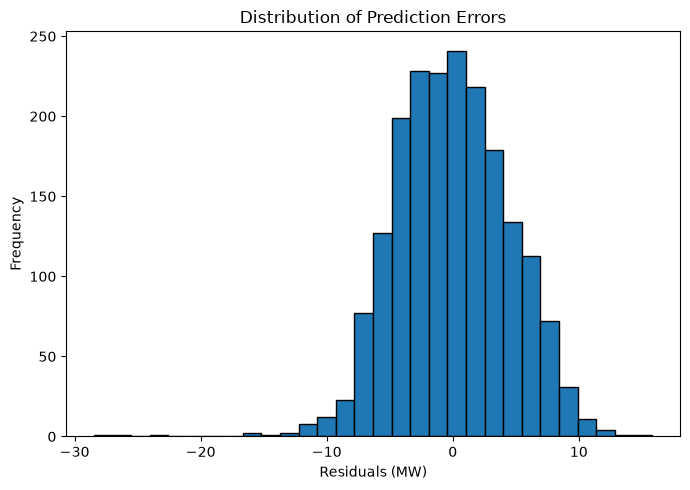

  Feature  Coefficient
0      AT    -1.985900
1       V    -0.232094
2      AP     0.062200
3      RH    -0.158118
Intercept: 454.5691145894146


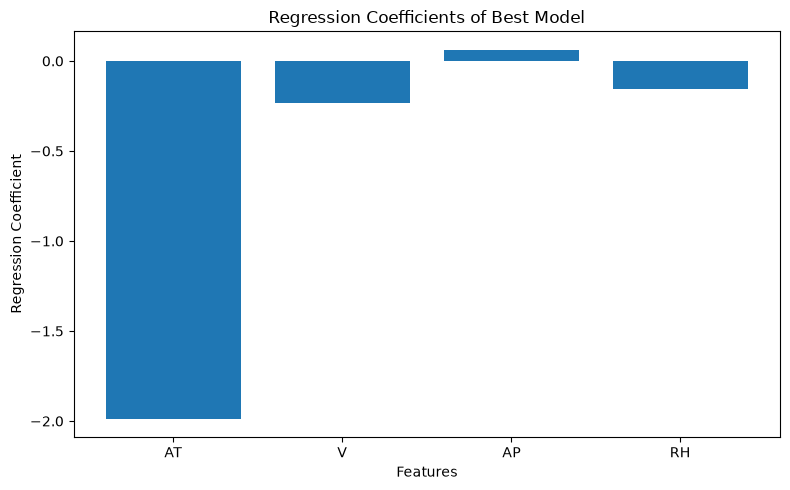

,Actual PE,Predicted PE,Residual
2513,455.27,455.680208,-0.410208
9411,436.31,438.732122,-2.422122
8745,440.68,434.164440,6.515560
9085,434.40,438.769546,-4.369546
4950,482.06,479.888329,2.171671
2755,436.07,439.499474,-3.429474
563,452.48,448.840102,3.639898
5834,435.22,434.809190,0.410810
6850,432.93,435.097364,-2.167364
4359,466.46,472.947629,-6.487629


In [9]:

best_row = results_df.sort_values(by="RMSE").iloc[0]

best_features = best_row["Features"].split(" + ")

print("Best features:", best_features)


X_train_best = X_train[best_features]
X_test_best = X_test[best_features]


final_model = LinearRegression()
final_model.fit(X_train_best, y_train)


y_pred_best = final_model.predict(X_test_best)

mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)

print("Final Model Performance")
print("-----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    LinearRegression(),
    X_train_best,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

print("5-Fold Cross Validation Results")
print("--------------------------------")

print("Average MAE:", -cv_results["test_MAE"].mean())
print("Average RMSE:", -cv_results["test_RMSE"].mean())
print("Average R2:", cv_results["test_R2"].mean())



plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_best, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Predicted Power Output (MW)")
plt.title("Actual vs Predicted Power Output")

plt.tight_layout()

plt.savefig(
    "../plots/Model_Evaluation/actual_vs_predicted.png"
)

plt.show()

residuals = y_test - y_pred_best

plt.figure(figsize=(7, 5))

plt.scatter(y_pred_best, residuals, alpha=0.5)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Power Output (MW)")
plt.ylabel("Residuals (MW)")
plt.title("Residuals vs Predicted Values")

plt.tight_layout()

plt.savefig(
    "../plots/Model_Evaluation/residuals_vs_predicted.png"
)

plt.show()



plt.figure(figsize=(7, 5))

plt.hist(residuals, bins=30, edgecolor="black")

plt.xlabel("Residuals (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.tight_layout()

plt.savefig(
    "../plots/Model_Evaluation/residual_histogram.png"
)

plt.show()

coefficient_df = pd.DataFrame({
    "Feature": best_features,
    "Coefficient": final_model.coef_
})

print(coefficient_df)
print("Intercept:", final_model.intercept_)




plt.figure(figsize=(8, 5))

plt.bar(
    coefficient_df["Feature"],
    coefficient_df["Coefficient"]
)

plt.xlabel("Features")
plt.ylabel("Regression Coefficient")
plt.title("Regression Coefficients of Best Model")

plt.tight_layout()

plt.savefig(
    "../plots/Model_Evaluation/regression_coefficients.png"
)

plt.show()



prediction_df = pd.DataFrame({
    "Actual PE": y_test,
    "Predicted PE": y_pred_best,
    "Residual": residuals
})

prediction_df.to_csv(
    "../plots/Model_Evaluation/predictions.csv",
    index=False
)

display(prediction_df.head(10))